# Mesh и MPGAA*: четыре варианта

Этот ноутбук читает проверенные сохранённые данные новой серии. Повторять временные запуски не требуется. Полный протокол, инварианты и ограничения находятся в [report.pdf](report.pdf) и [README](../../cpp/mpgaa_mesh/README.md).

Boundary совместно проверяет префиксы; Selective использует допустимый incumbent и границы ветвей; Delta подписывается на свободные префиксы и препятствия-свидетели; Policy ищет tight-цепочку среди нескольких альтернатив. После освобождений все варианты сначала восстанавливают допустимость эвристики.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'cpp/mpgaa_mesh').is_dir())
AD = ROOT/'cpp/mpgaa_mesh/results/full/analysis'
checks = json.loads((AD/'analysis.json').read_text())
display({k:checks[k] for k in ['status','timed_runs','memory_runs','scenarios','timed_planner_calls','exact_cost_disagreements','independent_dijkstra_comparisons','capped_calls','memory_matched_rows']})
cases = pd.read_csv(AD/'case_metrics.csv')
summary = pd.read_csv(AD/'summary.csv')
new = ['boundary_mpgaa','selective_mpgaa','delta_mpgaa','policy_mpgaa']

{'status': 'passed',
 'timed_runs': 11922,
 'memory_runs': 3974,
 'scenarios': 378,
 'timed_planner_calls': 429312,
 'exact_cost_disagreements': 0,
 'independent_dijkstra_comparisons': 6488,
 'capped_calls': 9,
 'memory_matched_rows': 146512}

## Полное время и полнота

Сначала берётся медиана трёх повторов внутри конфигурации, затем геометрическое среднее парных отношений. Значение больше 1 выгодно кандидату. Ускорения условны на завершении обоих методов; replay считает доказанную недостижимость корректным ответом, миссии требуют достижения цели. Интервалы — описательный bootstrap по картам, не оценка независимых запросов.

,cohort,control,method,episode_speedup,episode_speedup_lo,episode_speedup_hi,online_speedup,paired,configurations
0,replay,car16,boundary_mpgaa,1.636526,1.486347,1.893477,2.085034,90,90
1,navigation_dynamic,car16,boundary_mpgaa,1.567109,1.501882,1.650451,1.957329,37,48
2,navigation_unknown,car16,boundary_mpgaa,1.661484,1.541878,1.779224,1.778285,24,24
3,mission,car16,boundary_mpgaa,2.024559,1.672201,2.393272,2.303743,15,16
4,navigation_dynamic,grid8,boundary_mpgaa,1.057336,1.017025,1.099651,1.043193,79,80
5,mission,grid8,boundary_mpgaa,1.009586,0.991474,1.028562,1.014561,24,24
6,replay,grid8,boundary_mpgaa,1.042420,1.022486,1.057471,1.017930,96,96
7,replay,car16,selective_mpgaa,1.349625,1.201900,1.589845,1.784362,90,90
8,navigation_dynamic,car16,selective_mpgaa,1.257754,1.170991,1.323275,1.785484,37,48
9,navigation_unknown,car16,selective_mpgaa,1.368080,1.284615,1.456119,2.006994,24,24


sum  size
cohort             control method                    
mission            car16   boundary_mpgaa    15    16
                           delta_mpgaa       15    16
                           policy_mpgaa      15    16
                           selective_mpgaa   15    16
                   grid8   boundary_mpgaa    24    24
                           delta_mpgaa       24    24
                           policy_mpgaa      24    24
                           selective_mpgaa   24    24
navigation_dynamic car16   boundary_mpgaa    37    48
                           delta_mpgaa       37    48
                           policy_mpgaa      37    48
                           selective_mpgaa   37    48
                   grid8   boundary_mpgaa    79    80
                           delta_mpgaa       79    80
                           policy_mpgaa      78    80
                           selective_mpgaa   79    80
navigation_unknown car16   boundary_mpgaa    24    24
                           delta_mpgaa       24    24
                           policy_mpgaa      24    24
                           selective_mpgaa   24    24
replay             car16   boundary_mpgaa    90    90
                           delta_mpgaa       90    90
                           policy_mpgaa      90    90
                           selective_mpgaa   90    90
                   grid8   boundary_mpgaa    96    96
                           delta_mpgaa       96    96
                           policy_mpgaa      96    96
                           selective_mpgaa   96    96

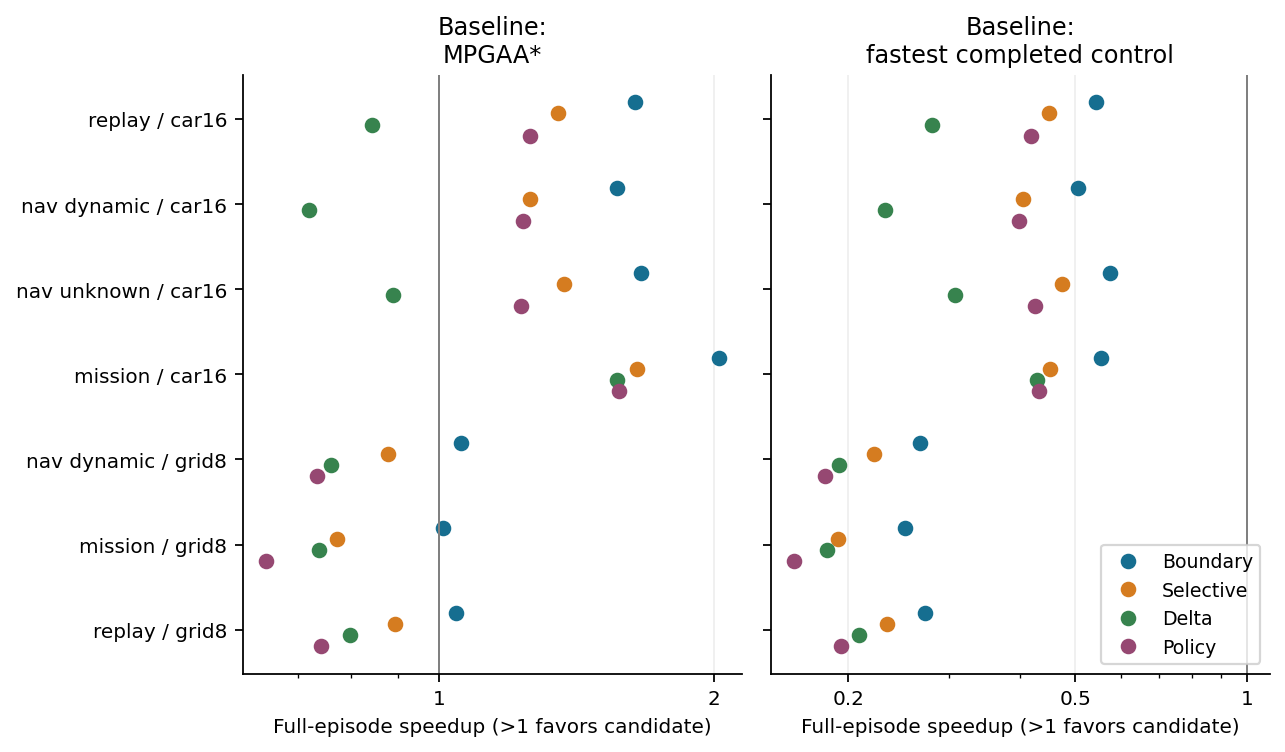

In [2]:
display(summary[summary.method.isin(new) & summary.baseline.eq('mpgaa')][['cohort','control','method','episode_speedup','episode_speedup_lo','episode_speedup_hi','online_speedup','paired','configurations']])
display(cases[cases.method.isin(new)].groupby(['cohort','control','method']).complete.agg(['sum','size']))
display(Image(filename=str(ROOT/'docs/mpgaa_mesh/figures/episode_speedup.png'), width=960))

## Карты и сильные контроли

`best_control` выбирает самый быстрый по полному эпизоду завершившийся контроль в каждой конфигурации. Это описательная огибающая, выбранная после измерений. В навигации у методов собственные траектории и наблюдения; парными являются конфигурации симулятора, а не тождественные последовательности запросов.

,control,map,method,episode_speedup,online_speedup,paired,configurations
1080,car16,AR0700,boundary_mpgaa,0.776926,0.659538,4,4
1083,car16,Berlin,boundary_mpgaa,0.597449,0.289048,5,5
1086,car16,MA_maze96,boundary_mpgaa,0.219706,0.015700,8,8
1090,car16,MA_random96,boundary_mpgaa,0.574646,0.301854,7,7
1094,car16,MA_room96,boundary_mpgaa,0.623150,0.348722,7,7
...,...,...,...,...,...,...,...
1230,grid8,arena,policy_mpgaa,0.139919,0.410938,8,8
1231,grid8,random50_p10,policy_mpgaa,0.216411,0.357876,8,8
1234,grid8,random50_p20,policy_mpgaa,0.176395,0.304987,8,8
1237,grid8,random50_p30,policy_mpgaa,0.211024,0.340088,8,8


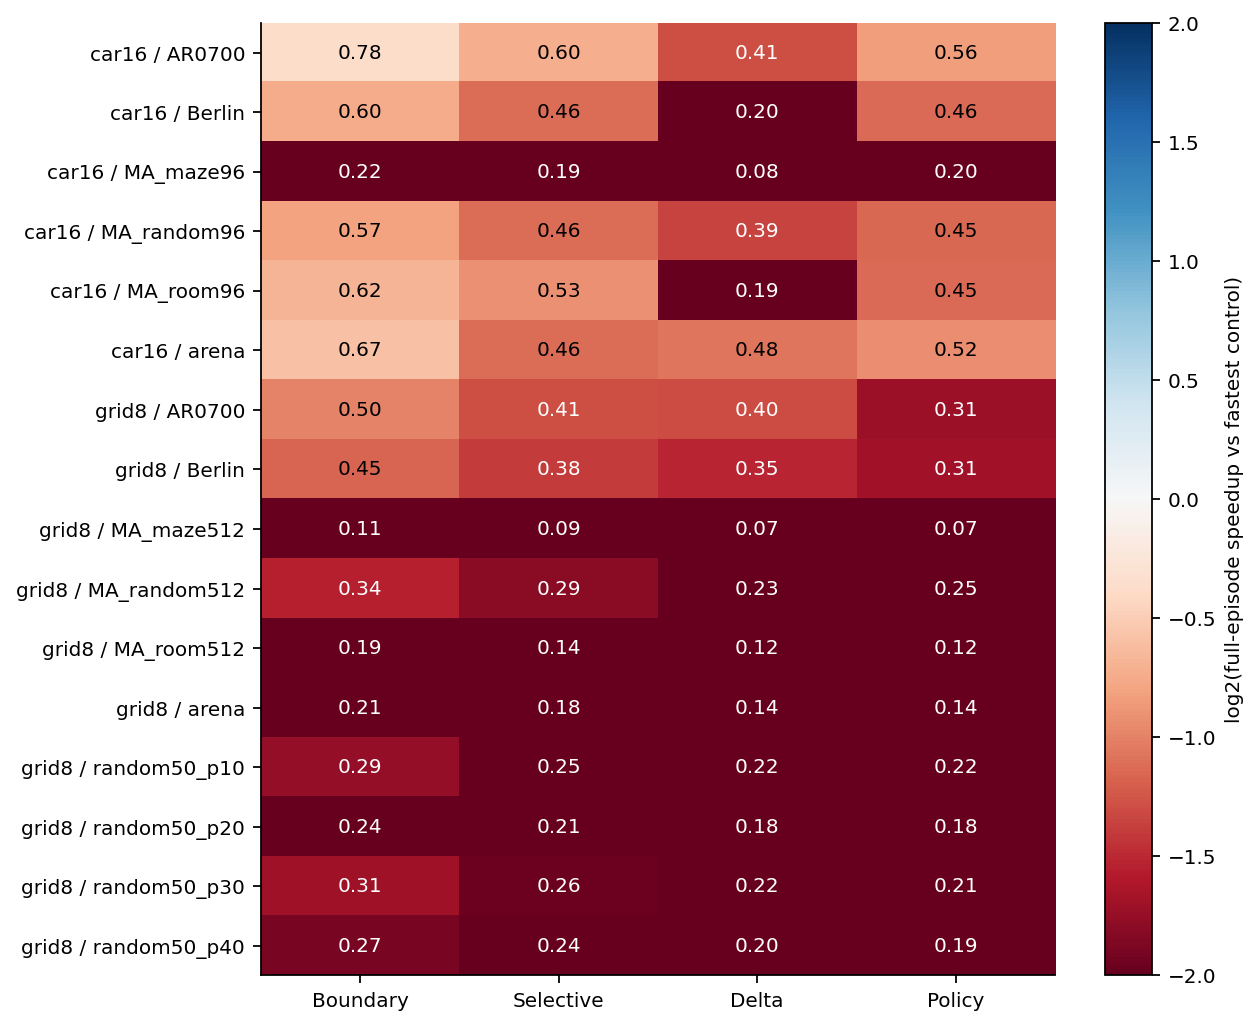

In [3]:
maps = pd.read_csv(AD/'map_pairs.csv')
view = maps[maps.cohort.eq('navigation_dynamic') & maps.baseline.eq('best_control') & maps.method.isin(new)]
display(view[['control','map','method','episode_speedup','online_speedup','paired','configurations']])
display(Image(filename=str(ROOT/'docs/mpgaa_mesh/figures/navigation_maps.png'), width=900))

## Абляции и память

`selective_no_prune` отключает только отсечение, сохраняя incumbent. `selective_geom` использует геометрическую оценку в границах ветвей, сохраняя обученный A*. Память получена отдельным проходом запрошенных C++ heap-байтов и не является RSS. Времена этого прохода не сравниваются.

,control,baseline,episode_speedup,online_speedup,paired
169,car16,selective_no_prune,1.004050,0.984351,90
170,grid8,selective_no_prune,0.976057,0.965492,96
179,car16,selective_geom,0.975121,0.956066,90
180,grid8,selective_geom,0.968291,0.956164,96


,cohort,control,method,expansions,checked_cells,notify_probes,heuristic_pops,backend_calls,certified,activated_cells,...,mesh_nodes,bound_evals,pruned_branches,pruned_primitives,watch_hits,validity_flips,witness_stops,policy_probes,policy_hits,alternate_uses
1,mission,car16,boundary_mpgaa,627379,6391713,1112616,0,741,0,0,...,6391713,0,0,0,0,0,211495,0,0,0
2,mission,car16,delta_mpgaa,627379,6156584,116343,0,741,0,0,...,6156584,0,0,0,116343,230732,220484,0,0,0
7,mission,car16,policy_mpgaa,621147,6403415,1112616,0,743,367,0,...,6403415,0,0,0,0,0,212727,763658,683,272
8,mission,car16,selective_mpgaa,627379,5546003,1112616,0,741,0,0,...,5546003,8954320,580026,3101714,0,0,192845,0,0,0
10,mission,grid8,boundary_mpgaa,14552,84952,25424,0,933,0,0,...,84952,0,0,0,0,0,5709,0,0,0
11,mission,grid8,delta_mpgaa,14552,88731,13691,0,933,0,0,...,88731,0,0,0,13691,13691,16117,0,0,0
17,mission,grid8,policy_mpgaa,11475,89664,25464,0,919,755,0,...,89664,0,0,0,0,0,7073,40549,864,1478
18,mission,grid8,selective_mpgaa,14552,77703,25424,0,933,0,0,...,77703,32192,20372,20372,0,0,5237,0,0,0
20,navigation_dynamic,car16,boundary_mpgaa,1833437,51168072,6950280,1947338,407,0,0,...,51168072,0,0,0,0,0,3554481,0,0,0
21,navigation_dynamic,car16,delta_mpgaa,1833437,51661790,1840943,1947338,407,0,0,...,51661790,0,0,0,1840943,3898160,3722079,0,0,0


median          max
control method                                
car16   boundary_mpgaa   1.516891   221.965826
        delta_mpgaa      3.983249  1142.375065
        policy_mpgaa     1.706329   222.119135
        selective_mpgaa  1.573854   238.132600
grid8   boundary_mpgaa   0.155518    14.729305
        delta_mpgaa      0.346032    37.099309
        policy_mpgaa     0.196936    19.595280
        selective_mpgaa  0.164398    14.754265

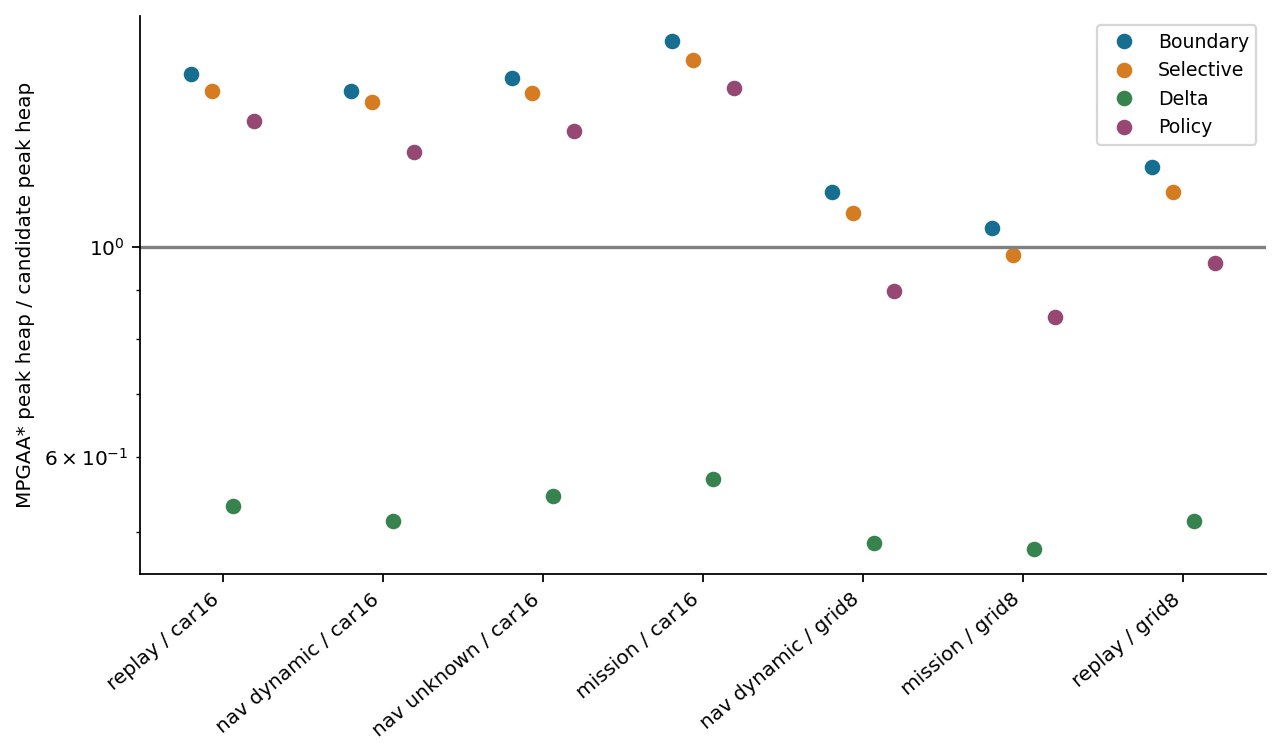

In [4]:
display(summary[summary.cohort.eq('replay') & summary.method.eq('selective_mpgaa') & summary.baseline.isin(['selective_no_prune','selective_geom'])][['control','baseline','episode_speedup','online_speedup','paired']])
display(pd.read_csv(AD/'work.csv').query('method in @new'))
display(cases[cases.method.isin(new)].groupby(['control','method']).peak_heap_bytes.agg(['median','max'])/2**20)
display(Image(filename=str(ROOT/'docs/mpgaa_mesh/figures/memory.png'), width=900))